# Set Up

In [1]:
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

!pip install torchinfo
from torchinfo import summary

import requests

# Eleuther's tokenizer
tokenizer = AutoTokenizer.from_pretrained('EleutherAI/gpt-neo-125m')
tokenizer.pad_token_id = tokenizer.encode(' ')[0]

# load in two GPTneo's and push to GPU
model_alice = AutoModelForCausalLM.from_pretrained('EleutherAI/gpt-neo-125m')
model_edgar = AutoModelForCausalLM.from_pretrained('EleutherAI/gpt-neo-125m')

# GPU
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
model_alice = model_alice.to(device)
model_edgar = model_edgar.to(device)

# Through the Looking Glass (aka Alice in Wornderland)
text = requests.get('https://www.gutenberg.org/cache/epub/11/pg11.txt').text
alice_tokens = torch.tensor(tokenizer.encode(text), dtype=torch.long)

# Edgar Allen Poe
text = requests.get('https://www.gutenberg.org/cache/epub/2148/pg2148.txt').text
edgar_tokens = torch.tensor(tokenizer.encode(text), dtype=torch.long)

config.json:   0%|          | 0.00/1.01k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/357 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/160 [00:00<?, ?it/s]

[transformers] GPTNeoForCausalLM LOAD REPORT from: EleutherAI/gpt-neo-125m
Key                                                   | Status     |  | 
------------------------------------------------------+------------+--+-
transformer.h.{0...11}.attn.attention.masked_bias     | UNEXPECTED |  | 
transformer.h.{0, 2, 4, 6, 8, 10}.attn.attention.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


generation_config.json:   0%|          | 0.00/119 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/160 [00:00<?, ?it/s]

[transformers] GPTNeoForCausalLM LOAD REPORT from: EleutherAI/gpt-neo-125m
Key                                                   | Status     |  | 
------------------------------------------------------+------------+--+-
transformer.h.{0...11}.attn.attention.masked_bias     | UNEXPECTED |  | 
transformer.h.{0, 2, 4, 6, 8, 10}.attn.attention.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (52948 > 2048). Running this sequence through the model will result in indexing errors


# FineTune

In [2]:
# ALICE optimizer
optimizer_alice = torch.optim.AdamW(model_alice.parameters(), lr=5e-5, weight_decay=.01)

# EDGAR optimizer
optimizer_edgar = torch.optim.AdamW(model_edgar.parameters(), lr=5e-5, weight_decay=.01)

In [3]:
# training parameters
seq_len     = 256 # max sequence length
batch_size  = 16
num_samples = 476

In [4]:
token_probs = np.zeros((num_samples, 3))

# initialize losses
loss_alice = np.zeros(num_samples)
loss_edgar = np.zeros(num_samples)

# loop over training
for sampl_i in range(num_samples):

  ### --- ALICE fine-tuning ---
  # get a batch of data
  ix = torch.randint(len(alice_tokens)-seq_len, size = (batch_size,))
  X  = alice_tokens[ix[:,None] + torch.arange(seq_len)].to(device)

  # forward pass and get loss
  model_alice.zero_grad() # we can also use optimizer.zero_grad() which is more traditional approach
  outputs = model_alice(X, labels = X) # fine crossentropy loss (t, t+1) HuggingFace interface

  # backprop and store loss
  outputs.loss.backward() # we don't have specified loss since its defined in model_alice so we need to refer to it manually
  optimizer_alice.step()
  loss_alice[sampl_i] = outputs.loss.item()
  ### -------------------------

  ### --- EDGAR fine-tuning ---
  # get the batch of data
  ix = torch.randint(len(edgar_tokens)-seq_len, size = (batch_size,))
  X  = edgar_tokens[ix[:,None] + torch.arange(seq_len)].to(device)

  # forward pass and get loss
  model_edgar.zero_grad()
  outputs = model_edgar(X, labels = X)

  # backprop and store loss
  outputs.loss.backward()
  optimizer_edgar.step()
  loss_edgar[sampl_i] = outputs.loss.item()
  ### --------------------------

  # update progress display
  if sampl_i % 77 == 0:
    print(f'Sample {sampl_i:4}/{num_samples}, losses (Alice/Edgar): {loss_alice[sampl_i]:.4f} / {loss_edgar[sampl_i]:.4f}')

Sample    0/476, losses (Alice/Edgar): 2.5391 / 2.6353
Sample   77/476, losses (Alice/Edgar): 1.7520 / 2.2536
Sample  154/476, losses (Alice/Edgar): 1.0504 / 2.0846
Sample  231/476, losses (Alice/Edgar): 0.6780 / 1.7665
Sample  308/476, losses (Alice/Edgar): 0.4838 / 1.7796
Sample  385/476, losses (Alice/Edgar): 0.2756 / 1.6915
Sample  462/476, losses (Alice/Edgar): 0.2256 / 1.4876


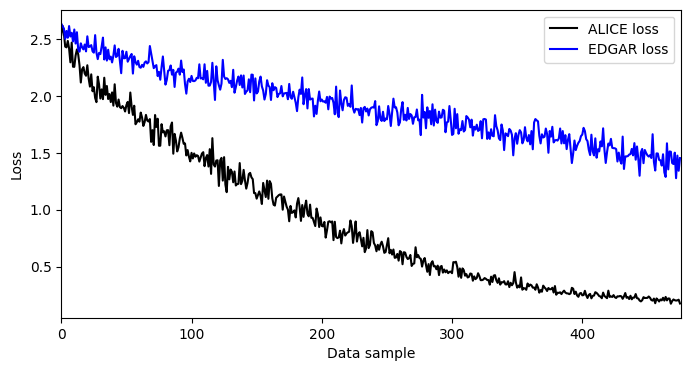

In [5]:
plt.figure(figsize = (8,4))
plt.plot(loss_alice, 'k', markersize = 8, label = 'ALICE loss')
plt.plot(loss_edgar, 'b', markersize = 8, label = 'EDGAR loss')

plt.legend()
plt.gca().set(xlabel='Data sample', ylabel='Loss', xlim = [0, num_samples])
plt.show()

# Chat

In [6]:
out_alice = tokenizer.encode('Hello, my name is Alice', return_tensors='pt').to(device)
print('\n\n** Alice says:\n', tokenizer.decode(out_alice[0].cpu()))

for _ in range(5):

  # Edgar's turn
  out_edgar = model_edgar.generate(out_alice, max_new_tokens=50, do_sample=True, pad_token_id=tokenizer.pad_token_id)
  print(f'\n\n** Edgar says (total token count: {len(out_edgar[0])}):\n',
        tokenizer.decode(out_edgar[0][len(out_alice[0]):].cpu()))

  # Alice's turn
  out_alice = model_alice.generate(out_edgar, max_new_tokens=50, do_sample=True, pad_token_id=tokenizer.pad_token_id)
  print(f'\n\n** Alice says (total token count: {len(out_alice[0])}):\n',
        tokenizer.decode(out_alice[0][len(out_edgar[0]):].cpu()))

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.




** Alice says:
 Hello, my name is Alice


** Edgar says (total token count: 56):
  Brown.

      I am the proprietor of a manufacturing paper-mill on the
      Great Western Railway, called the “Miles Hole,” in Haringon—


** Alice says (total token count: 106):
 the
“hole” is about 2,100 feet high. The main workhouse I’ve been on is
inside the wholeey—the rest of the ground is written up in pencil.

I


** Edgar says (total token count: 156):
  did not hesitate to tell you that the amount of labor you were
 required to raise a mill in, is not less than four hundred dollars;
 that upon reaching the bottom of the Hole, I would like very much to
 have


** Alice says (total token count: 206):
  you to-day, you know, but for the curious things happening in
 those minutes—the fact is, though I do not like to be called�, I
 like to think I do, if I had only waited a little


** Edgar says (total token count: 256):
  longer.

One day I took some unusual steps, and there appeared to my
 ima